# Exploratory Data Analysis and Insights on Daily Bike Sharing Using Pandas

### Beginner-to-Intermediate Pandas Practice Notebook

This notebook is designed for students who are learning how to explore time-based and weather-related data using **Pandas**.

The exercises begin with basic DataFrame operations and gradually introduce:

- Loading and inspecting a CSV file
- Checking data quality
- Converting text into dates
- Selecting, filtering, and sorting records
- Exploring encoded categories
- Grouping and aggregating daily observations
- Creating derived columns
- Examining correlations
- Creating basic time-series visualizations
- Exporting an analyzed DataFrame


## About the Dataset

The **BikeSharingDaily.csv** dataset contains **731 daily observations** from the Capital Bikeshare system for 2011 and 2012.

It contains **16 columns**:

| Column | Description |
|---|---|
| `record_id` | Unique row identifier |
| `date` | Observation date |
| `season` | Season code: 1 winter, 2 spring, 3 summer, 4 fall |
| `year` | Year code: 0 for 2011 and 1 for 2012 |
| `month` | Month number from 1 to 12 |
| `holiday` | Whether the day was a holiday |
| `weekday` | Day-of-week code, where 0 is Sunday and 6 is Saturday |
| `working_day` | Whether the day was neither a weekend nor a holiday |
| `weather_situation` | Encoded weather category from clear to severe weather |
| `temperature` | Normalized daily temperature |
| `feels_like_temperature` | Normalized perceived temperature |
| `humidity` | Normalized humidity |
| `wind_speed` | Normalized wind speed |
| `casual_users` | Number of casual bike users |
| `registered_users` | Number of registered bike users |
| `total_rentals` | Total daily bike rentals |

The source also provides an hourly file, but this assignment uses the smaller daily file so students can focus on clear Pandas operations and simple time-based analysis.

The original abbreviated column names were replaced with descriptive names. The record values were not changed.

**Source:** [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)  
**License:** CC BY 4.0


## Learning Goal

By completing this assignment, you will practice a complete beginner-to-intermediate Pandas workflow. You will work with dates, compare rental activity across seasons and weather conditions, create useful demand indicators, and visualize changes over time.


## 1. Loading and Understanding the Dataset

### Question 1
Import the Pandas library using the alias `pd` and read **BikeSharingDaily.csv** into a DataFrame named `df`.


In [1]:
import pandas as pd
df = pd.read_csv('D:\Liha-Tech Assignments\Pandas\Bike_Sharing_Daily\BikeSharingDaily.csv')

### Question 2
Display the first **5 rows** of the dataset.


In [2]:
df.head()

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Question 3
Display the last **5 rows** of the dataset.


In [3]:
df.tail()

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796
730,731,2012-12-31,1,1,12,0,1,1,2,0.215833,0.223487,0.577500,0.154846,439,2290,2729


### Question 4
Find the total number of **rows and columns** in the dataset.


In [4]:
df.shape

(731, 16)

### Question 5
Display all the **column names** in the dataset.


In [5]:
df.columns

Index(['record_id', 'date', 'season', 'year', 'month', 'holiday', 'weekday',
       'working_day', 'weather_situation', 'temperature',
       'feels_like_temperature', 'humidity', 'wind_speed', 'casual_users',
       'registered_users', 'total_rentals'],
      dtype='str')

### Question 6
Display the **data type of each column**.


In [6]:
df.dtypes

record_id                   int64
date                          str
season                      int64
year                        int64
month                       int64
holiday                     int64
weekday                     int64
working_day                 int64
weather_situation           int64
temperature               float64
feels_like_temperature    float64
humidity                  float64
wind_speed                float64
casual_users                int64
registered_users            int64
total_rentals               int64
dtype: object

### Question 7
Display a complete summary of the DataFrame using `info()`.


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   record_id               731 non-null    int64  
 1   date                    731 non-null    str    
 2   season                  731 non-null    int64  
 3   year                    731 non-null    int64  
 4   month                   731 non-null    int64  
 5   holiday                 731 non-null    int64  
 6   weekday                 731 non-null    int64  
 7   working_day             731 non-null    int64  
 8   weather_situation       731 non-null    int64  
 9   temperature             731 non-null    float64
 10  feels_like_temperature  731 non-null    float64
 11  humidity                731 non-null    float64
 12  wind_speed              731 non-null    float64
 13  casual_users            731 non-null    int64  
 14  registered_users        731 non-null    int64  
 15  

## 2. Checking Data Quality and Converting Dates

### Question 8
Display the number of **missing values in each column**.


In [8]:
df.isnull().sum()

record_id                 0
date                      0
season                    0
year                      0
month                     0
holiday                   0
weekday                   0
working_day               0
weather_situation         0
temperature               0
feels_like_temperature    0
humidity                  0
wind_speed                0
casual_users              0
registered_users          0
total_rentals             0
dtype: int64

### Question 9
Calculate the **total number of missing values** in the entire DataFrame.


In [9]:
df.isnull().sum().sum()

np.int64(0)

### Question 10
Check the number of **duplicate rows** in the dataset.


In [10]:
df.duplicated().sum()

np.int64(0)

### Question 11
Create a new DataFrame named `df_clean` with duplicate rows removed, then display its shape.


In [11]:
df_clean = df.drop_duplicates()
df.shape

(731, 16)

### Question 12
Convert the `date` column in `df_clean` to Pandas datetime format using `pd.to_datetime()` and display its new data type.


In [12]:
df_clean['date']=pd.to_datetime(df_clean['date'])

## 3. Selecting Rows and Columns

### Question 13
Select and display only the **total_rentals** column from `df_clean`.


In [13]:
df_clean['total_rentals']

0       985
1       801
2      1349
3      1562
4      1600
       ... 
726    2114
727    3095
728    1341
729    1796
730    2729
Name: total_rentals, Length: 731, dtype: int64

### Question 14
Select and display the **date, season, weather_situation, temperature, and total_rentals** columns.


In [14]:
df[['date','season','weather_situation','temperature','total_rentals']]

,date,season,weather_situation,temperature,total_rentals
0,2011-01-01,1,2,0.344167,985
1,2011-01-02,1,2,0.363478,801
2,2011-01-03,1,1,0.196364,1349
3,2011-01-04,1,1,0.200000,1562
4,2011-01-05,1,1,0.226957,1600
...,...,...,...,...,...
726,2012-12-27,1,2,0.254167,2114
727,2012-12-28,1,2,0.253333,3095
728,2012-12-29,1,2,0.253333,1341
729,2012-12-30,1,1,0.255833,1796


### Question 15
Using `iloc`, display the first **5 rows and first 6 columns**.


In [15]:
df.iloc[:5,:6]

,record_id,date,season,year,month,holiday
0,1,2011-01-01,1,0,1,0
1,2,2011-01-02,1,0,1,0
2,3,2011-01-03,1,0,1,0
3,4,2011-01-04,1,0,1,0
4,5,2011-01-05,1,0,1,0


### Question 16
Using `loc`, display rows **10 to 15** for the columns **date, temperature, humidity, registered_users, and total_rentals**.


In [16]:
df.loc[10:15,['date','temperature','humidity','registered_users','total_rentals']]

,date,temperature,humidity,registered_users,total_rentals
10,2011-01-11,0.169091,0.686364,1220,1263
11,2011-01-12,0.172727,0.599545,1137,1162
12,2011-01-13,0.165000,0.470417,1368,1406
13,2011-01-14,0.160870,0.537826,1367,1421
14,2011-01-15,0.233333,0.498750,1026,1248
15,2011-01-16,0.231667,0.483750,953,1204


## 4. Categories and Descriptive Statistics

### Question 17
Count the number of daily records for each **season** using `value_counts()`.


In [17]:
df['season'].value_counts()

season
3    188
2    184
1    181
4    178
Name: count, dtype: int64

### Question 18
Count the records in each **weather_situation** category.


In [18]:
df['weather_situation'].value_counts()

weather_situation
1    463
2    247
3     21
Name: count, dtype: int64

### Question 19
Display descriptive statistics for the numeric columns using `describe()`.


In [19]:
df.describe()

,record_id,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


### Question 20
Calculate the **mean total_rentals** for all days.


In [20]:
df['total_rentals'].mean()

np.float64(4504.3488372093025)

### Question 21
Find the day with the **highest total_rentals**.


In [21]:
df.loc[df['total_rentals'].idxmax()]

record_id                        624
date                      2012-09-15
season                             3
year                               1
month                              9
holiday                            0
weekday                            6
working_day                        0
weather_situation                  1
temperature                 0.608333
feels_like_temperature      0.585867
humidity                    0.501667
wind_speed                  0.247521
casual_users                    3160
registered_users                5554
total_rentals                   8714
Name: 623, dtype: object

### Question 22
Calculate the average numbers of **casual_users** and **registered_users**.


In [22]:
df['casual_users'].mean()
df['registered_users'].mean()

np.float64(3656.172366621067)

## 5. Filtering and Sorting

### Question 23
Display all days where **total_rentals exceeded 5,000**.


In [23]:
df[df['total_rentals'] > 5000]

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
119,120,2011-04-30,2,0,4,0,6,0,1,0.472500,0.464021,0.503333,0.235075,1965,3347,5312
140,141,2011-05-21,2,0,5,0,6,0,1,0.602500,0.571975,0.626667,0.120650,2258,3547,5805
153,154,2011-06-03,2,0,6,0,5,1,1,0.620000,0.587133,0.354167,0.253121,898,4414,5312
154,155,2011-06-04,2,0,6,0,6,0,1,0.635000,0.594696,0.456250,0.123142,1869,3473,5342
163,164,2011-06-13,2,0,6,0,1,1,1,0.635000,0.601654,0.494583,0.305350,863,4157,5020
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
712,713,2012-12-13,4,1,12,0,4,1,1,0.295833,0.294188,0.485833,0.174129,425,5107,5532
713,714,2012-12-14,4,1,12,0,5,1,1,0.281667,0.294192,0.642917,0.131229,429,5182,5611
714,715,2012-12-15,4,1,12,0,6,0,1,0.324167,0.338383,0.650417,0.106350,767,4280,5047
717,718,2012-12-18,4,1,12,0,2,1,1,0.410833,0.409708,0.666250,0.221404,433,5124,5557


### Question 24
Display all records where **holiday is equal to 1**.


In [24]:
df[df['holiday']==1]

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
16,17,2011-01-17,1,0,1,1,1,0,2,0.175833,0.176771,0.537500,0.194017,117,883,1000
51,52,2011-02-21,1,0,2,1,1,0,2,0.303333,0.284075,0.605000,0.307846,195,912,1107
104,105,2011-04-15,2,0,4,1,5,0,1,0.446667,0.441913,0.671250,0.226375,642,2484,3126
149,150,2011-05-30,2,0,5,1,1,0,1,0.733333,0.671092,0.685000,0.131225,1549,2549,4098
184,185,2011-07-04,3,0,7,1,1,0,2,0.726667,0.665417,0.637917,0.081479,3065,2978,6043
247,248,2011-09-05,3,0,9,1,1,0,2,0.673333,0.625646,0.790417,0.212696,1236,2115,3351
282,283,2011-10-10,4,0,10,1,1,0,1,0.570833,0.542925,0.733750,0.042304,1514,3603,5117
314,315,2011-11-11,4,0,11,1,5,0,1,0.324167,0.306817,0.446250,0.314675,440,2928,3368
327,328,2011-11-24,4,0,11,1,4,0,1,0.373333,0.372471,0.549167,0.167304,560,935,1495
359,360,2011-12-26,1,0,12,1,1,0,1,0.321739,0.315535,0.506957,0.239465,430,887,1317


### Question 25
Display working days where **total_rentals exceeded 6,000**.


In [25]:
df[df['total_rentals']>6000]

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
184,185,2011-07-04,3,0,7,1,1,0,2,0.726667,0.665417,0.637917,0.081479,3065,2978,6043
438,439,2012-03-14,1,1,3,0,3,1,1,0.572500,0.548617,0.507083,0.115062,997,5315,6312
439,440,2012-03-15,1,1,3,0,4,1,1,0.557500,0.532825,0.579583,0.149883,1005,5187,6192
441,442,2012-03-17,1,1,3,0,6,0,2,0.514167,0.505046,0.755833,0.110704,3155,4681,7836
443,444,2012-03-19,1,1,3,0,1,1,1,0.545000,0.532821,0.728750,0.162317,982,5171,6153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
679,680,2012-11-10,4,1,11,0,6,0,1,0.389167,0.393937,0.645417,0.057846,2090,4446,6536
680,681,2012-11-11,4,1,11,0,0,0,1,0.420833,0.421713,0.659167,0.127500,2290,4562,6852
681,682,2012-11-12,4,1,11,1,1,0,1,0.485000,0.475383,0.741667,0.173517,1097,5172,6269
702,703,2012-12-03,4,1,12,0,1,1,1,0.452500,0.455796,0.767500,0.082721,555,5679,6234


### Question 26
Using `query()`, display days where **temperature is greater than 0.7** and **humidity is below 0.6**.


In [26]:
df.query('temperature >0.7 and humidity <0.6')

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
152,153,2011-06-02,2,0,6,0,4,1,1,0.715000,0.643942,0.305000,0.292287,736,4232,4968
157,158,2011-06-07,2,0,6,0,2,1,1,0.707500,0.655950,0.597917,0.187808,763,4070,4833
159,160,2011-06-09,2,0,6,0,4,1,2,0.808333,0.757579,0.568333,0.149883,563,3352,3915
174,175,2011-06-24,3,0,6,0,5,1,1,0.724167,0.656583,0.573333,0.222025,969,4022,4991
179,180,2011-06-29,3,0,6,0,3,1,1,0.728333,0.654688,0.497917,0.261821,848,4377,5225
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,591,2012-08-13,3,1,8,0,1,1,1,0.720833,0.662254,0.545417,0.136212,1207,5676,6883
593,594,2012-08-16,3,1,8,0,4,1,1,0.719167,0.654688,0.519167,0.141796,1338,6267,7605
594,595,2012-08-17,3,1,8,0,5,1,1,0.723333,0.242400,0.570833,0.231354,1483,5665,7148
607,608,2012-08-30,3,1,8,0,4,1,1,0.706667,0.652779,0.590417,0.077117,1172,6541,7713


### Question 27
Sort `df_clean` by **total_rentals in descending order** and display the first 10 rows.


In [27]:
df.sort_values(by='total_rentals',ascending=False).head(10)

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
623,624,2012-09-15,3,1,9,0,6,0,1,0.608333,0.585867,0.501667,0.247521,3160,5554,8714
637,638,2012-09-29,4,1,9,0,6,0,1,0.542500,0.530296,0.542917,0.227604,2589,5966,8555
630,631,2012-09-22,3,1,9,0,6,0,1,0.650000,0.610488,0.646667,0.283583,2512,5883,8395
447,448,2012-03-23,2,1,3,0,5,1,2,0.601667,0.570067,0.694167,0.116300,2469,5893,8362
504,505,2012-05-19,2,1,5,0,6,0,1,0.600000,0.566908,0.456250,0.083975,3410,4884,8294
617,618,2012-09-09,3,1,9,0,0,0,1,0.610000,0.578925,0.547500,0.224496,2570,5657,8227
571,572,2012-07-25,3,1,7,0,3,1,1,0.724167,0.654054,0.450000,0.164800,1383,6790,8173
629,630,2012-09-21,3,1,9,0,5,1,1,0.599167,0.571971,0.668750,0.154229,1250,6917,8167
643,644,2012-10-05,4,1,10,0,5,1,1,0.615000,0.580187,0.627500,0.106350,1516,6640,8156
518,519,2012-06-02,2,1,6,0,6,0,1,0.583333,0.566288,0.549167,0.186562,2795,5325,8120


### Question 28
Display the **5 days with the highest registered-user counts**.


In [28]:
df.sort_values(by='registered_users',ascending=False).head(5)

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
634,635,2012-09-26,4,1,9,0,3,1,1,0.635000,0.596613,0.630833,0.244400,787,6946,7733
629,630,2012-09-21,3,1,9,0,5,1,1,0.599167,0.571971,0.668750,0.154229,1250,6917,8167
648,649,2012-10-10,4,1,10,0,3,1,1,0.514167,0.503142,0.630833,0.187821,780,6911,7691
662,663,2012-10-24,4,1,10,0,3,1,1,0.587500,0.558721,0.636250,0.072779,795,6898,7693
641,642,2012-10-03,4,1,10,0,3,1,2,0.657500,0.599133,0.793750,0.066546,728,6844,7572


## 6. Grouping and Aggregation

### Question 29
Calculate the **average total_rentals for each season**.


In [29]:
df.groupby('season')['total_rentals'].mean()

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: total_rentals, dtype: float64

### Question 30
Calculate the **average total_rentals for each weather_situation**.


In [30]:
df.groupby('weather_situation')['total_rentals'].mean()

weather_situation
1    4876.786177
2    4035.862348
3    1803.285714
Name: total_rentals, dtype: float64

### Question 31
Calculate total rentals for each combination of **year and month**.


In [31]:
df.groupby(['year','month'])['total_rentals'].sum()

year  month
0     1         38189
      2         48215
      3         64045
      4         94870
      5        135821
      6        143512
      7        141341
      8        136691
      9        127418
      10       123511
      11       102167
      12        87323
1     1         96744
      2        103137
      3        164875
      4        174224
      5        195865
      6        202830
      7        203607
      8        214503
      9        218573
      10       198841
      11       152664
      12       123713
Name: total_rentals, dtype: int64

### Question 32
For each working-day category, calculate the **minimum, maximum, and mean total_rentals** using `agg()`.


In [32]:
df.groupby('working_day')['total_rentals'].agg(['min','max','mean'])

,min,max,mean
working_day,,,
0,605,8714,4330.168831
1,22,8362,4584.820000


### Question 33
Determine which month number has the **highest average total_rentals**.


In [33]:
df.groupby('month')['total_rentals'].mean().sort_values(ascending=False).head(1)

month
6    5772.366667
Name: total_rentals, dtype: float64

## 7. Creating and Modifying Columns

### Question 34
Create a new column named **registered_share** by dividing `registered_users` by `total_rentals`.


In [34]:
df['registered_share'] = df['registered_users'] / df['total_rentals']
df

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals,registered_share
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,0.663959
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,0.836454
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,0.911045
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,0.930858
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,0.948750
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114,0.883160
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095,0.791922
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341,0.881432
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796,0.797327


### Question 35
Create a column named **demand_level** using `apply()` with a `lambda` function. Store `High` when `total_rentals` is greater than or equal to 5,000; otherwise store `Normal`.


In [35]:
df['demand_level'] = df['total_rentals'].apply(lambda x : 'High' if x>=5000 else 'Normal')
df

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals,registered_share,demand_level
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,0.663959,Normal
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,0.836454,Normal
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,0.911045,Normal
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,0.930858,Normal
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,0.948750,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114,0.883160,Normal
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095,0.791922,Normal
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341,0.881432,Normal
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796,0.797327,Normal


### Question 36
Create a column named **day_type**. Store `Weekend` when `weekday` is 0 or 6; otherwise store `Weekday`.


In [36]:
df['day_type'] = df['weekday'].apply(lambda x: 'Weekend' if x==0 | 6 else 'Weekday')
df

,record_id,date,season,year,month,holiday,weekday,working_day,weather_situation,temperature,feels_like_temperature,humidity,wind_speed,casual_users,registered_users,total_rentals,registered_share,demand_level,day_type
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,0.663959,Normal,Weekend
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,0.836454,Normal,Weekday
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,0.911045,Normal,Weekday
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,0.930858,Normal,Weekday
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,0.948750,Normal,Weekday
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,0.226642,0.652917,0.350133,247,1867,2114,0.883160,Normal,Weekday
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,0.255046,0.590000,0.155471,644,2451,3095,0.791922,Normal,Weekday
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,0.242400,0.752917,0.124383,159,1182,1341,0.881432,Normal,Weekend
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,0.231700,0.483333,0.350754,364,1432,1796,0.797327,Normal,Weekday


## 8. Correlation, Visualization, and Export

### Question 37
Create a correlation matrix for **temperature, humidity, wind_speed, casual_users, registered_users, and total_rentals**.


In [37]:
df[['temperature','humidity','wind_speed','casual_users','registered_users','total_rentals']].corr()

,temperature,humidity,wind_speed,casual_users,registered_users,total_rentals
temperature,1.000000,0.126963,-0.157944,0.543285,0.540012,0.627494
humidity,0.126963,1.000000,-0.248489,-0.077008,-0.091089,-0.100659
wind_speed,-0.157944,-0.248489,1.000000,-0.167613,-0.217449,-0.234545
casual_users,0.543285,-0.077008,-0.167613,1.000000,0.395282,0.672804
registered_users,0.540012,-0.091089,-0.217449,0.395282,1.000000,0.945517
total_rentals,0.627494,-0.100659,-0.234545,0.672804,0.945517,1.000000


### Question 38
Create a **line chart** showing `total_rentals` over `date` with an appropriate title and axis labels.


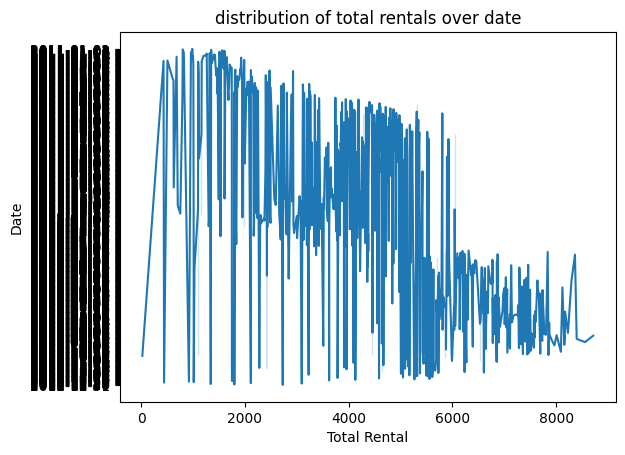

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.lineplot(x='total_rentals',y='date',data=df)
plt.title('distribution of total rentals over date')
plt.xlabel('Total Rental')
plt.ylabel('Date')
plt.show()


### Question 39
Create a **bar chart** showing the average total rentals for each season.


<Axes: xlabel='season', ylabel='total_rentals'>

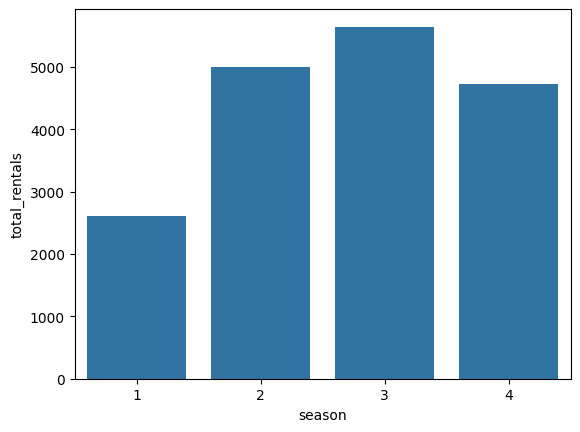

In [39]:
import seaborn as sns
sns.barplot(df.groupby('season')['total_rentals'].mean())

### Question 40
Save `df_clean` as **BikeSharingDaily_Analyzed.csv** using `to_csv()` without saving the index.


In [40]:
df_clean.to_csv('BikeSharingDaily_Analyzed.csv',index=False)

## End of Practice

Try to solve each question independently before checking any reference material.

The main goal is to become comfortable with dates, grouped summaries, and simple time-based visualizations before moving to forecasting or predictive modeling.
